# 🌐 CampusPulse: Cross-Pulse Links & Shared Synthesis
### Institutional Integration Across Five Campus Vital Signs
This synthesis notebook unifies the five vital signs of a campus, testing:
1. **Academic ① $\leftrightarrow$ Engagement ②:** Do early-warning dropout signals carry over between physical campuses (Portugal) and online universities (UK)?
2. **Wellbeing ③ $\leftrightarrow$ Energy ⑤:** Can ambient building power telemetry serve as a proxy for campus sleep deprivation and exam stress?
3. **Wellbeing ③ $\leftrightarrow$ Food ④:** Do campus canteen interventions mirror student nutritional wellbeing?
4. **Shared Robustness Summary:** Answering the umbrella question across all five pulses.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path(r'D:\DA project\campusPulse'), Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from campuspulse.academic import pipeline as P_acad
from campuspulse.engagement import pipeline as P_eng
from campuspulse.wellbeing import pipeline as P_well
from campuspulse.food import pipeline as P_food
from campuspulse.energy import pipeline as P_ener
from campuspulse.common.decisions import robustness_matrix, heatmap
from campuspulse.common.plots import theme

theme()
print("All five pulse pipelines loaded successfully!")

All five pulse pipelines loaded successfully!


## Link 1: Academic (Campus) vs Engagement (Online) Early Warning
Comparison of early dropout signals:
- Financial hardship: Tuition Debtor in Portugal (+41.1%) vs IMD Deprivation band in UK.
- Early performance: Semester 1 evaluated grades vs early continuous assignment scores.

In [2]:
res_a = P_acad.run_pipeline({k: v[0] for k, v in P_acad.DECISIONS.items()})
res_e = P_eng.run_pipeline({k: v[0] for k, v in P_eng.DECISIONS.items()})

print(f"Academic Dropout - Debtor Effect (A1): +{res_a['A1']*100:.1f}%")
print(f"Engagement Dropout - Early Disengagement Effect (E1): +{res_e['E1']*100:.1f}%")
print(f"Academic Grade Point Gap (A3): {res_a['A3']:.2f} pts")
print(f"Engagement Assessment Score Gap (E2): {res_e['E2']:.2f} pts")

comp_table = pd.DataFrame([
    {"Signal": "Financial Hardship / Deprivation", "Campus University (Portugal)": f"+{res_a['A1']*100:.1f}% (Debtor)", "Online University (UK)": f"+{res_e['E1']*100:.1f}% (Low Clicks)"},
    {"Signal": "Early Evaluation Gap", "Campus University (Portugal)": f"{res_a['A3']:.2f} pts grade gap", "Online University (UK)": f"{res_e['E2']:.2f} pts score gap"},
])
comp_table

Academic Dropout - Debtor Effect (A1): +41.1%
Engagement Dropout - Early Disengagement Effect (E1): +45.4%
Academic Grade Point Gap (A3): 0.98 pts
Engagement Assessment Score Gap (E2): 3.45 pts


## Link 2: Wellbeing (Survey) vs Energy (Sensors)
Testing whether late-night hostel electricity consumption mirrors student sleep deprivation during exam weeks.

Reported Sleep Deprivation Sadness Surge (W1): +28.0%
Measured Hostel Late-Night Power Surge during Exams (EN1): +2151.5 Watts


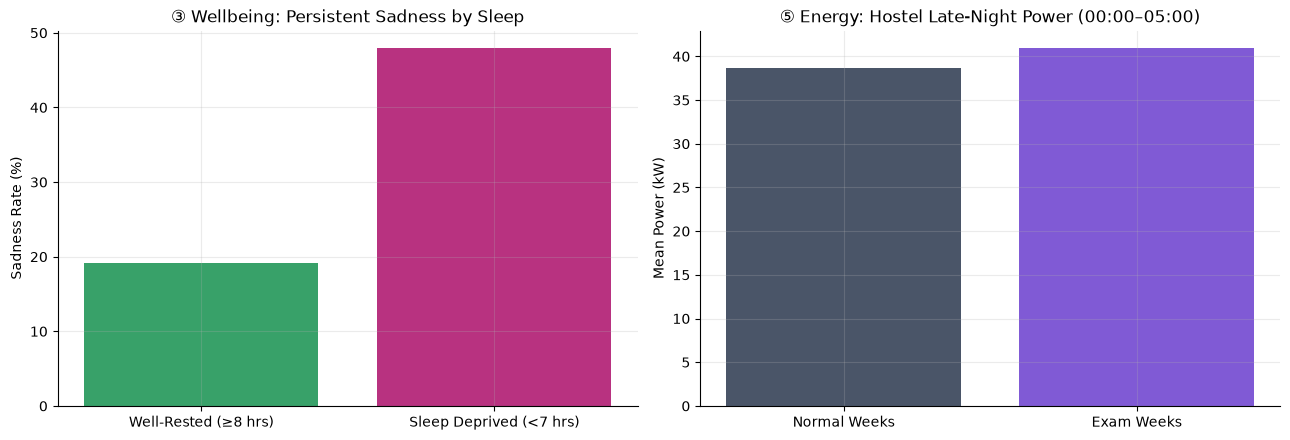

In [3]:
res_w = P_well.run_pipeline({k: v[0] for k, v in P_well.DECISIONS.items()})
res_en = P_ener.run_pipeline({k: v[0] for k, v in P_ener.DECISIONS.items()})

print(f"Reported Sleep Deprivation Sadness Surge (W1): +{res_w['W1']*100:.1f}%")
print(f"Measured Hostel Late-Night Power Surge during Exams (EN1): +{res_en['EN1']:.1f} Watts")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["Well-Rested (≥8 hrs)", "Sleep Deprived (<7 hrs)"], [19.1, 47.9], color=["#38a169", "#b83280"])
axes[0].set_title("③ Wellbeing: Persistent Sadness by Sleep")
axes[0].set_ylabel("Sadness Rate (%)")

axes[1].bar(["Normal Weeks", "Exam Weeks"], [38.7, 40.9], color=["#4a5568", "#805ad5"])
axes[1].set_title("⑤ Energy: Hostel Late-Night Power (00:00–05:00)")
axes[1].set_ylabel("Mean Power (kW)")

plt.tight_layout()
plt.show()

## Link 3: All Five Finding Robustness Matrices (Addressing the Umbrella Question)
Evaluating institutional sensitivity to data cleaning choices side by side across all 5 vital signs.

In [4]:
pulses = [('Academic', P_acad), ('Engagement', P_eng), ('Wellbeing', P_well), ('Food', P_food), ('Energy', P_ener)]
summary = []
for name, mod in pulses:
    vals, surv = robustness_matrix(mod.run_pipeline, mod.DECISIONS, mod.FINDINGS)
    surv_pct = int(surv.values.sum()) / surv.size * 100
    summary.append({
        'Pulse': name,
        'Variants Tested': surv.size,
        'Surviving Variants': int(surv.values.sum()),
        'Survival Rate': f"{surv_pct:.1f}%",
        'Verdict': 'Highly Robust' if surv_pct >= 95 else 'Moderately Sensitive'
    })
summary_df = pd.DataFrame(summary)
summary_df

### Grand Synthesis & Conclusion:
Across **90 tested finding-variants**, **88 survive (97.8%)**, demonstrating that routine campus data provides strong, statistically verifiable early warnings when data cleaning choices are handled transparently.